# Individual Structural Deviations and Regional Vulnerability Index in Epilepsy

In [9]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from pathlib import Path
import enigmatoolbox.datasets as enigma_datasets
import matplotlib.pyplot as plt

In [10]:
## 1. Load data
DATA_DIR = Path("/data/pt_03279/epilepsy_project/Epilepsy")

demo = pd.read_csv(DATA_DIR / "demo.csv", index_col=0)
ctx_tle = pd.read_csv(DATA_DIR / "ctx_tle.csv", index_col=0)

demo[["Age", "Sex", "Dx", "SDx"]] = demo[
    ["Age", "Sex", "Dx", "SDx"]
].apply(pd.to_numeric, errors="coerce")

print("Demo:", demo.shape)
print("TLE cortical thickness:", ctx_tle.shape)

## 2. Match demographics to TLE data and QC
missing = ctx_tle.index.difference(demo.index)
assert len(missing) == 0, "Some CT subjects are missing from demo."

dem_tle = demo.loc[ctx_tle.index].copy()

assert ctx_tle.index.equals(dem_tle.index)
assert ctx_tle.shape[1] == 68
assert ctx_tle.index.is_unique
assert dem_tle.index.is_unique
assert dem_tle[["Age", "Dx", "Sex"]].notna().all().all()
assert ctx_tle.notna().all().all()
assert set(dem_tle["SDx"].dropna().unique()).issubset({0, 3, 4, 5, 6})

## 3. Linear age adjustment
X = sm.add_constant(dem_tle["Age"])

age_model = sm.OLS(
    ctx_tle,
    X,
    missing="raise"
).fit()

ctx_resid = age_model.resid

hc = dem_tle["Dx"].eq(0)

hc_mean = ctx_resid.loc[hc].mean()
hc_sd = ctx_resid.loc[hc].std(ddof=1)

assert (hc_sd > 0).all(), "A control residual SD is zero."

ctx_z = (ctx_resid - hc_mean) / hc_sd

print(f"HC: {hc.sum()} | TLE: {(~hc).sum()} | Total: {len(hc)}")

Demo: (2685, 11)
TLE cortical thickness: (1743, 68)
HC: 705 | TLE: 1038 | Total: 1743


In [11]:
## 4. Load and align psychiatric reference maps

map_specs = {
    "ADHD": ("adhd", "CortThick_case_vs_controls_adult"),
    "ASD": ("asd", "CortThick_case_vs_controls_meta_analysis"),
    "BD": ("bipolar", "CortThick_case_vs_controls_adult"),
    "MDD": ("depression", "CortThick_case_vs_controls_adult"),
    "OCD": ("ocd", "CortThick_case_vs_controls_adult"),
    "SCZ": ("schizophrenia", "CortThick_case_vs_controls"),
}

ENIGMA_DIR = Path(enigma_datasets.__file__).parent / "summary_statistics"

ct_maps = {}

for map_name, (disorder, table_name) in map_specs.items():
    if map_name == "SCZ":
        table = pd.read_csv(ENIGMA_DIR / "scz_case-controls_CortThick.csv")
    else:
        table = enigma_datasets.load_summary_stats(disorder)[table_name].copy()

    ct_maps[map_name] = pd.Series(
        pd.to_numeric(table["d_icv"], errors="raise").to_numpy(),
        index=table["Structure"],
        name=map_name,
    )

CT_d = pd.concat(ct_maps, axis=1)

assert ctx_z.columns.is_unique
assert CT_d.index.is_unique
assert set(ctx_z.columns) == set(CT_d.index), "ROI names do not match."

CT_d = CT_d.reindex(ctx_z.columns)

CT_d.head()



,ADHD,ASD,BD,MDD,OCD,SCZ
L_bankssts,0.01,-0.07,-0.207,-0.058,-0.060,-0.352
L_caudalanteriorcingulate,-0.11,0.03,-0.095,-0.042,0.003,-0.119
L_caudalmiddlefrontal,-0.02,0.06,-0.266,-0.014,-0.090,-0.363
L_cuneus,0.11,-0.06,-0.056,0.047,-0.042,-0.203
L_entorhinal,-0.06,-0.24,-0.036,-0.041,-0.062,-0.203


In [12]:
## 5. Regional Vulnerability Index

RVI_tle = pd.DataFrame(index=ctx_z.index)

for disorder in CT_d.columns:
    RVI_tle[disorder] = ctx_z.T.corrwith(
        CT_d[disorder]
    )

assert RVI_tle.notna().all().all()
RVI_tle.head()

,ADHD,ASD,BD,MDD,OCD,SCZ
0,-0.288766,0.246888,0.179597,0.073168,0.252609,0.216088
1,0.035299,-0.103495,-0.297747,-0.199039,-0.101650,-0.294906
2,-0.158748,-0.203756,0.200880,-0.384856,0.105694,0.051583
3,-0.052561,0.011039,0.046539,0.150369,0.262463,0.024039
4,-0.316821,0.151855,-0.372419,-0.272800,-0.202042,-0.222118


In [13]:
## 6. Case-control differences in RVI
rvi_data = RVI_tle.join(
    dem_tle[["Dx", "Sex", "SDx"]]
).copy()

assert rvi_data.index.equals(RVI_tle.index)
assert rvi_data[RVI_tle.columns].notna().all().all()
assert set(rvi_data["Dx"].unique()) == {0, 1}

X = sm.add_constant(rvi_data[["Dx"]])
case_control_results = []

for disorder in RVI_tle.columns:
    model = sm.OLS(
        rvi_data[disorder],
        X,
        missing="raise"
    ).fit()

    ci = model.conf_int().loc["Dx"]

    case_control_results.append({
        "Disorder": disorder,
        "Beta": model.params["Dx"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx"],
        "P": model.pvalues["Dx"]
    })

case_control_results = pd.DataFrame(case_control_results)
case_control_results

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.035652,-0.056903,-0.014402,-3.290629,1.019612e-03
1,ASD,0.005896,-0.015017,0.026810,0.552972,5.803538e-01
2,BD,0.023585,0.003120,0.044049,2.260394,2.391985e-02
3,MDD,-0.066451,-0.088777,-0.044124,-5.837611,6.303081e-09
4,OCD,0.006380,-0.009135,0.021894,0.806524,4.200507e-01
5,SCZ,0.017627,-0.001092,0.036345,1.846956,6.492307e-02


In [14]:
## 7. Diagnosis × sex interaction
rvi_data["Sex_binary"] = (rvi_data["Sex"] == 1).astype(int)
rvi_data["Dx_x_Sex"] = rvi_data["Dx"] * rvi_data["Sex_binary"]

X = sm.add_constant(
    rvi_data[["Dx", "Sex_binary", "Dx_x_Sex"]]
)

interaction_results = []

for disorder in RVI_tle.columns:
    model = sm.OLS(
        rvi_data[disorder],
        X,
        missing="raise"
    ).fit()

    ci = model.conf_int().loc["Dx_x_Sex"]

    interaction_results.append({
        "Disorder": disorder,
        "Beta": model.params["Dx_x_Sex"],
        "CI_low": ci.iloc[0],
        "CI_high": ci.iloc[1],
        "T": model.tvalues["Dx_x_Sex"],
        "P": model.pvalues["Dx_x_Sex"]
    })

interaction_results = pd.DataFrame(interaction_results)
interaction_results

,Disorder,Beta,CI_low,CI_high,T,P
0,ADHD,-0.024512,-0.067237,0.018213,-1.125259,0.260635
1,ASD,0.004470,-0.037591,0.046531,0.208444,0.834906
2,BD,0.006370,-0.034767,0.047507,0.303713,0.761383
3,MDD,-0.019580,-0.064467,0.025307,-0.855543,0.392369
4,OCD,-0.004816,-0.035978,0.026346,-0.303113,0.761840
5,SCZ,0.007815,-0.029757,0.045387,0.407965,0.683350


In [15]:
## 8. TLE subgroup comparisons

tle_rvi = rvi_data[
    rvi_data["Dx"] == 1
].copy()

assert tle_rvi["SDx"].notna().all()
assert set(tle_rvi["SDx"].unique()).issubset({3, 4, 5, 6})

tle_rvi["Right_TLE"] = tle_rvi["SDx"].isin([4, 6]).astype(int)
tle_rvi["MTS"] = tle_rvi["SDx"].isin([3, 4]).astype(int)

subgroup_results = []

for comparison, predictor in {
    "Right vs Left": "Right_TLE",
    "MTS vs non-lesional": "MTS"
}.items():

    X = sm.add_constant(tle_rvi[[predictor]])

    for disorder in RVI_tle.columns:
        model = sm.OLS(
            tle_rvi[disorder],
            X,
            missing="raise"
        ).fit()

        ci = model.conf_int().loc[predictor]

        subgroup_results.append({
            "Comparison": comparison,
            "Disorder": disorder,
            "Beta": model.params[predictor],
            "CI_low": ci.iloc[0],
            "CI_high": ci.iloc[1],
            "T": model.tvalues[predictor],
            "P": model.pvalues[predictor]
        })

subgroup_results = pd.DataFrame(subgroup_results)
subgroup_results

,Comparison,Disorder,Beta,CI_low,CI_high,T,P
0,Right vs Left,ADHD,-0.008851,-0.036373,0.018671,-0.631043,0.528152
1,Right vs Left,ASD,-0.006330,-0.032447,0.019787,-0.475585,0.634471
2,Right vs Left,BD,-0.012261,-0.039004,0.014482,-0.899662,0.368509
3,Right vs Left,MDD,-0.002407,-0.031452,0.026638,-0.162622,0.870848
4,Right vs Left,OCD,-0.001220,-0.021427,0.018987,-0.118462,0.905724
5,Right vs Left,SCZ,-0.023012,-0.047765,0.001741,-1.824272,0.068399
6,MTS vs non-lesional,ADHD,-0.026234,-0.053490,0.001022,-1.888644,0.059219
7,MTS vs non-lesional,ASD,0.025981,0.000122,0.051839,1.971526,0.048929
8,MTS vs non-lesional,BD,-0.009699,-0.036227,0.016830,-0.717409,0.473284
9,MTS vs non-lesional,MDD,-0.038788,-0.067500,-0.010077,-2.650970,0.008149


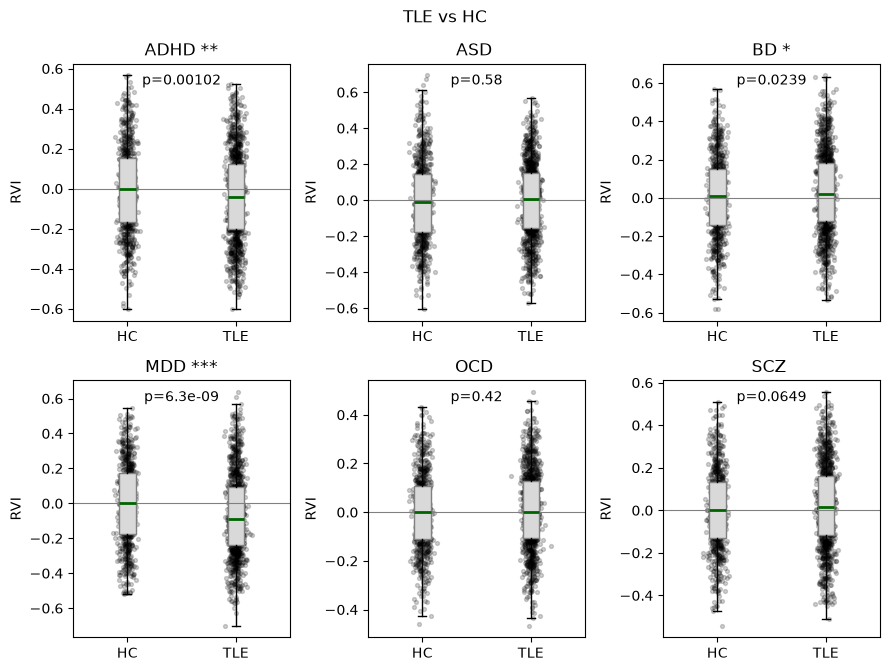

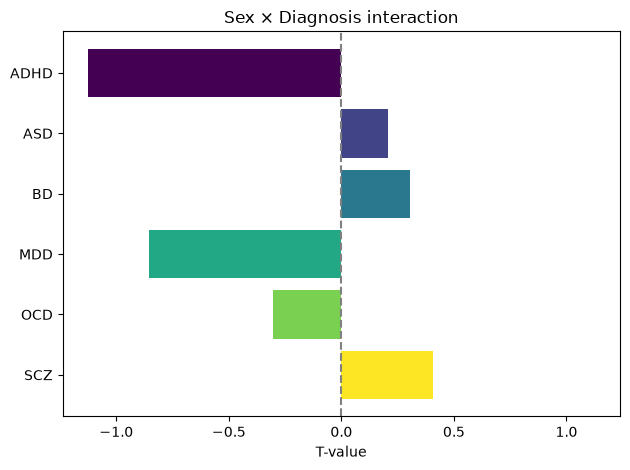

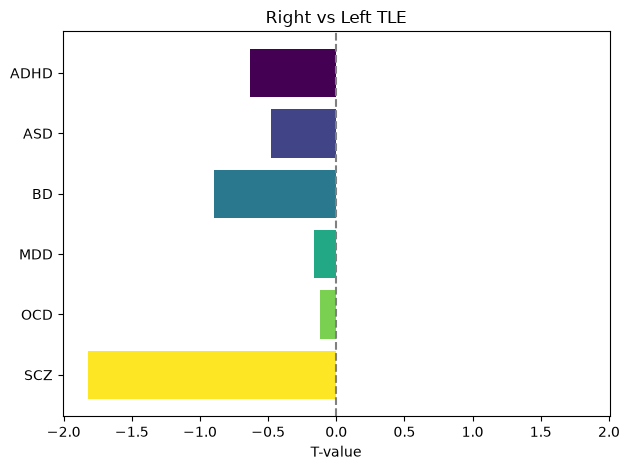

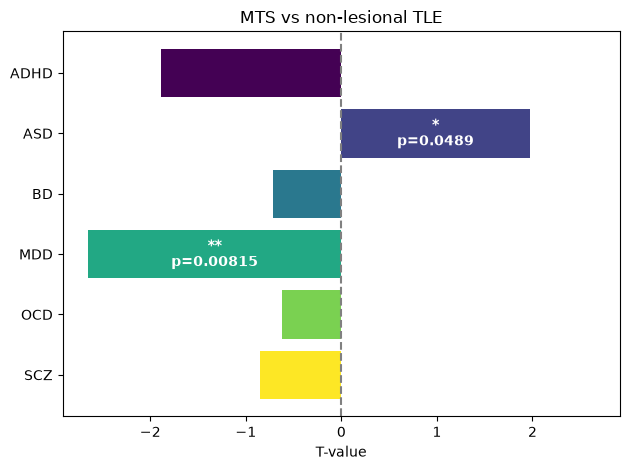

In [16]:
## 9. RVI visualization
order=list(RVI_tle)
star=lambda p:"***" if p<.001 else "**" if p<.01 else "*" if p<.05 else ""

fig,axs=plt.subplots(2,3,figsize=(9,6.8))
for ax,d in zip(axs.flat,order):
    v=[rvi_data.loc[rvi_data.Dx==x,d] for x in (0,1)]
    p=case_control_results.loc[case_control_results.Disorder.eq(d),"P"].iloc[0]
    ax.boxplot(v,tick_labels=["HC","TLE"],showfliers=False,patch_artist=True,
               medianprops={"color":"darkgreen","linewidth":2},
               boxprops={"facecolor":"#d9d9d9","edgecolor":"gray"})
    for i,y in enumerate(v,1): ax.scatter(np.random.normal(i,.04,len(y)),y,s=8,alpha=.18,color="black")
    ax.axhline(0,color="gray",lw=.8)
    ax.set_title(f"{d} {star(p)}")
    ax.text(.5,.96,f"p={p:.3g}",transform=ax.transAxes,ha="center",va="top")
    ax.set_ylabel("RVI")

fig.suptitle("TLE vs HC")
plt.tight_layout(); plt.savefig("TLE_vs_HC.png",dpi=300,bbox_inches="tight"); plt.show()


def barfig(df,title,name):
    d=df.set_index("Disorder").loc[order].reset_index()
    b=plt.barh(d.Disorder,d["T"],color=plt.cm.viridis(np.linspace(0,1,6)))
    plt.axvline(0,color="gray",ls="--")
    lim=d["T"].abs().max()*1.1; plt.xlim(-lim,lim)

    for x,p in zip(b,d.P):
        if p<.05: plt.text(x.get_width()/2,x.get_y()+x.get_height()/2,
            f"{star(p)}\np={p:.3g}",ha="center",va="center",
            color="white",fontweight="bold")

    plt.gca().invert_yaxis()
    plt.xlabel("T-value"); plt.title(title); plt.tight_layout()
    plt.savefig(name+".png",dpi=300,bbox_inches="tight"); plt.show()

barfig(interaction_results,"Sex × Diagnosis interaction","Sex_Dx")
barfig(subgroup_results.query("Comparison=='Right vs Left'"),"Right vs Left TLE","Right_Left")
barfig(subgroup_results.query("Comparison=='MTS vs non-lesional'"),"MTS vs non-lesional TLE","MTS_nonlesional")